# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated with cuDF & CuPy (No NumPy/Pandas)
# -----------------------------------------------------------------------
# Full workflow: Modules 1–17 with policy scenarios, deterministic & probabilistic analyses,
# CE-plane, CEAC, EVPI, tornado, subgroup, budget impact, equity,
# PSA histograms, CEAF, input summary, cost-mix stacked area, publication comparison.


# %% [markdown]
## 1. Imports & Setup

import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
from scipy.stats import beta

warnings.filterwarnings("ignore")
cp.random.seed(42)

# %% [markdown]
## 2. Global Parameters & GPU Constants

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035
POP_SIZE = 62000

# Demographics
SEVERITY_DIST = cp.array([0.70, 0.30])
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST = cp.array(
    [
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_CP = cp.array([74, 54])
ABS_MORT = cp.array(
    [
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)
MORT_HR = cp.array([2.0, 4.0])

defaul_yield = 0.45

# Fertility bands
FERT_AGE_SPEC = {
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}
# Build GPU lookup table for fertility rates
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Utilities
U_BASE_CP = cp.array([0.78, 0.65])
U_DECAY = 0.0005
U_DIAG = 0.02
U_CARER = 0.05

# Costs
COST_INP_CP = cp.array([5000, 15000])
COST_OUTP_CP = cp.array([1000, 3000])
COST_PHARM_CP = cp.array([200, 500])
EDU0 = cp.array([16107, 27903, 46733])
EDU1 = cp.array([18958, 30789, 49604])
RESPITE = 13024
MOBILITY = 2493
WELFARE_CP = cp.array([3000, 8000])
EMP_CP = cp.array([0, 10000, 0])

# Morbidity
MORB_KEYS = ["epilepsy", "asd", "mental"]
MORB_PROB = {"epilepsy": 0.25, "asd": 0.30, "mental": 0.35}
MORB_COST_CP = cp.array([2000, 1500, 1000])
MORB_QALY_CP = cp.array([0.04, 0.03, 0.05])

# %% [markdown]
## 3. Cohort Generator (GPU)


def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0, 5, n)).astype(int)


def gen_population_gpu(n, familial_prop, arm="prospective"):
    ages = sample_ages_gpu(n)
    sex = cp.random.choice(2, n)
    sev = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial = cp.random.random(n) < familial_prop
    diag = (
        cp.zeros(n, bool)
        if arm == "prospective"
        else (cp.random.random(n) < defaul_yield)
    )
    living = cp.random.choice(4, n, p=cp.array([0.2, 0.1, 0.3, 0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7, 0.2, 0.1]))
    uses_respite = cp.random.random(n) < 0.3
    needs_mobility = cp.random.random(n) < 0.2
    school = cp.where(ages < 5, -1, cp.where(ages < 12, 0, 1))
    support = cp.random.choice(3, n, p=cp.array([0.5, 0.3, 0.2]))
    ses = cp.random.choice(5, n)
    df = cudf.DataFrame(
        {
            "age": ages,
            "sex": sex,
            "severity": sev,
            "familial": familial,
            "diagnosed": diag,
            "living": living,
            "employment": employment,
            "uses_respite": uses_respite,
            "needs_mobility": needs_mobility,
            "school": school,
            "support": support,
            "ses": ses,
        }
    )
    df["annual_cost"] = 0.0
    df["annual_qaly"] = 0.0
    return df

# %% [markdown]
## 4. Population System (GPU)


class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop, arm="prospective"):
        self.arm = arm
        self.pop = gen_population_gpu(pop_size, familial_prop, arm)

    def _mortality(self):
        df = self.pop
        ages = df["age"].to_cupy()
        sev = df["severity"].to_cupy()
        surv = ABS_MORT[(ages // 5).astype(int)] * MORT_HR[sev]
        mask = (cp.random.random(len(ages)) > surv) & (ages < LIFE_EXP_CP[sev])
        self.pop = df.iloc[cp.where(mask)[0]].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df = self.pop
        moms = df[(df["sex"] == 0) & df["age"].between(15, 45)]
        if moms.empty:
            return
        mr = moms.merge(FERT_RATES_GPU, on=["severity", "age"], how="left").fillna(
            {"rate": 0}
        )
        rates = mr["rate"].values
        births = cp.random.random(len(rates)) < rates
        idx = cp.nonzero(births)[0]
        if len(idx) > 0:
            babies = gen_population_gpu(len(idx), familial_prop, self.arm)
            babies["age"] = 0
            flags = mr["familial"].iloc[idx.get()].reset_index(drop=True)
            babies["familial"] = flags
            self.pop = cudf.concat([df, babies], ignore_index=True)

    def _diagnosis(self, params):
        if self.arm != "prospective":
            return
        df = self.pop
        mask = (
            (~df["diagnosed"])
            & df["familial"]
            & (df["age"] >= params.get("min_test_age", 0))
        )
        cnt = int(mask.sum())
        if cnt > 0:
            df.loc[mask, "diagnosed"] = cp.random.random(cnt) < params["yield_wgs"]
        self.pop = df

    def _cost_qaly(self, year, params):
        df = self.pop
        disc = 1 / ((1 + DISCOUNT) ** (year - START_YEAR))
        sev = df["severity"].to_cupy()
        ages = df["age"].to_cupy()
        hc = (COST_INP_CP[sev] + COST_OUTP_CP[sev] + COST_PHARM_CP[sev]) * disc
        m0 = df["school"] == 0
        m1 = df["school"] == 1
        ec0 = EDU0[df.loc[m0, "support"].to_cupy()] * disc
        ec1 = EDU1[df.loc[m1, "support"].to_cupy()] * disc
        rc = df["uses_respite"].astype(int) * RESPITE * disc
        mc = -df["needs_mobility"].astype(int) * MOBILITY * disc
        wc = WELFARE_CP[sev] * disc
        emp = EMP_CP[df["employment"].to_cupy()] * disc
        base = cp.random.random(len(df))
        morb_cost = cp.zeros(len(df))
        morb_qaly = cp.zeros(len(df))
        for i, k in enumerate(MORB_KEYS):
            m = base < MORB_PROB[k]
            morb_cost += m.astype(float) * MORB_COST_CP[i] * disc
            morb_qaly += m.astype(float) * MORB_QALY_CP[i] * disc
        uq = U_BASE_CP[sev] * cp.exp(-U_DECAY * cp.clip(ages - 20, 0, None))
        total_qaly = (
            uq + df["diagnosed"].astype(int) * U_DIAG + U_CARER
        ) * disc - morb_qaly
        df["cost_health"] = hc
        df["cost_edu"] = 0.0
        df.loc[m0, "cost_edu"] = ec0
        df.loc[m1, "cost_edu"] = ec1
        df["cost_respite"] = rc
        df["cost_mobility"] = mc
        df["cost_welfare"] = wc
        df["cost_emp"] = emp
        df["cost_morbidity"] = morb_cost
        df["annual_cost"] = hc + df["cost_edu"] + rc + mc + wc + emp + morb_cost
        df["annual_qaly"] = total_qaly
        self.pop = df

    def step(self, year, params):
        self._mortality()
        self._fertility(params["familial_prop"])
        self._diagnosis(params)
        self._cost_qaly(year, params)

# %% [markdown]
## 5. Scenario Runner (retrospective vs prospective)

# %%
def run_scenario(params, pop_size=POP_SIZE):
    """
    Runs two arms ('retrospective' and 'prospective') for a given policy 'params'.
    Returns:
      - results: {'retrospective':(cost,qaly), 'prospective':(cost,qaly)}
      - intermediate: cuDF DataFrame with per-year floats
    """
    results = {}
    intermediate = []

    for arm in ("retrospective", "prospective"):
        # reset and seed the system
        sim = PopulationSystemGPU(pop_size, params["familial_prop"])
        cum_cost = 0.0
        cum_qaly = 0.0

        for t, yr in enumerate(YEARS):
            sim.step(params)
            disc = 1 / ((1 + DISCOUNT) ** t)

            # sum *on the GPU* and get a Python float
            cost_gpu = sim.pop["annual_cost"].sum()
            qaly_gpu = sim.pop["annual_qaly"].sum()
            cost_sum = float(cost_gpu.get())
            qaly_sum = float(qaly_gpu.get())

            cum_cost += cost_sum * disc
            cum_qaly += qaly_sum * disc

            # record exactly the floats for this arm & year
            intermediate.append(
                {
                    "arm": arm,
                    "year": yr,
                    "costs": cum_cost,
                    "qalys": cum_qaly,
                    # if you want SES‐equity here, too:
                    **{
                        f"ses_q{i}_pct": float((sim.pop["ses_q"] == i).mean() * 100)
                        for i in range(5)
                    },
                }
            )

        results[arm] = (cum_cost, cum_qaly)

    # one big cuDF DataFrame of clean, 1D floats
    int_df = cudf.DataFrame(intermediate)
    return results, int_df

# %% [markdown]
## 6. Deterministic Scenarios

scenarios = {"low": 0.10, "base": 0.165, "high": 0.23}
results = []
for name, val in scenarios.items():
    dc, dq = run_sim({"familial_prop": val, "yield_wgs": defaul_yield}, pop_size=20000)
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": dc / dq})
det_df = cudf.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)
plt.bar(
    det_df["scenario"].to_arrow().to_pylist(),
    [x / 1000 for x in det_df["ICER"].to_arrow().to_pylist()],
)
plt.title("Deterministic ICERs ($k/QALY)")
plt.show()

# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

psa_n = 300
psa_out = []
for i in range(psa_n):
    samp = {"familial_prop": beta.rvs(30, 150), "yield_wgs": beta.rvs(45, 55)}
    dc, dq = run_sim(samp, pop_size=8000)
    psa_out.append({"run": i, "dCost": dc, "dQALY": dq})
psa_df = cudf.DataFrame(psa_out)
psa_df.to_csv("psa_samples.csv", index=False)

# %% [markdown]
## 8. CE-Plane, CEAC & EVPI

wtp = cp.linspace(0, 150000, 40)
dcost = psa_df["dCost"].to_cupy()
dqaly = psa_df["dQALY"].to_cupy()
nb = dqaly[:, None] * wtp[None, :] - dcost[:, None]
# CE-Plane scatter
plt.scatter(dqaly.get(), dcost.get())
plt.xlabel("ΔQALY")
plt.ylabel("ΔCost")
plt.title("CE-Plane")
plt.show()
# CEAC
prob = (nb > 0).mean(axis=0)
plt.plot(wtp.get(), prob.get())
plt.title("CEAC")
plt.xlabel("WTP")
plt.ylabel("P(cost-effective)")
plt.show()
# EVPI
evpi = nb.max(axis=0) - cp.maximum(nb.mean(axis=0), 0)
plt.plot(wtp.get(), evpi.get())
plt.title("EVPI")
plt.xlabel("WTP")
plt.ylabel("EVPI")
plt.show()

# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

tornado = []
for param in ["yield_wgs", "familial_prop"]:
    base = defaul_yield if param == "yield_wgs" else 0.165
    for change in [-0.2, 0.2]:
        p = {"familial_prop": 0.165, "yield_wgs": defaul_yield}
        p[param] = base * (1 + change)
        dc, dq = run_sim(p, pop_size=10000)
        tornado.append(
            {"param": param, "change": f"{int(change * 100)}%", "ICER": dc / dq}
        )
tor_df = cudf.DataFrame(tornado)
labels = [
    f"{p} {c}"
    for p, c in zip(
        tor_df["param"].to_arrow().to_pylist(), tor_df["change"].to_arrow().to_pylist()
    )
]
icers = tor_df["ICER"].to_arrow().to_pylist()
plt.figure()
plt.barh(labels, [x / 1000 for x in icers])
plt.xlabel("ICER ($k/QALY)")
plt.title("Tornado Sensitivity")
plt.show()

# %% [markdown]
## 10. Subgroup Analyses

sg = []

# 1️⃣ Severity sub-groups
orig = SEVERITY_DIST.copy()
for sev, label in [(0, "Mild"), (1, "Moderate")]:
    SEVERITY_DIST[:] = cp.array([1.0 if i == sev else 0.0 for i in range(2)])
    d_cost, d_qaly = run_sim(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=15_000
    )
    sg.append({"group": f"Severity {label}", "ICER": d_cost / d_qaly})
SEVERITY_DIST[:] = orig  # restore baseline mix

# 2️⃣ Age-at-test sub-groups
for age in (0, 18, 30):
    d_cost, d_qaly = run_sim(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield, "min_test_age": age},
        pop_size=15_000,
    )
    sg.append({"group": f"MinTestAge {age}", "ICER": d_cost / d_qaly})

# 3️⃣ Time-horizon sub-analyses
(_, _), int_full = run_scenario(
    {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=15_000
)

dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]

for yrs_n in (10, 20, len(YEARS)):
    yr = START_YEAR + yrs_n - 1
    # extract single floats via Series boolean indexing + Arrow → Python list
    c1 = float(dfp["costs"][dfp["year"] == yr].to_arrow().to_pylist()[0])
    c0 = float(dfr["costs"][dfr["year"] == yr].to_arrow().to_pylist()[0])
    q1 = float(dfp["qalys"][dfp["year"] == yr].to_arrow().to_pylist()[0])
    q0 = float(dfr["qalys"][dfr["year"] == yr].to_arrow().to_pylist()[0])
    sg.append({"group": f"Horizon {yrs_n} yrs", "ICER": (c1 - c0) / (q1 - q0)})

# ---------- Plot ----------
sg_df = cudf.DataFrame(sg)
plt.figure()
plt.errorbar(
    sg_df["ICER"].to_arrow().to_pylist(),
    sg_df["group"].to_arrow().to_pylist(),
    xerr=[0.0] * len(sg_df),
    fmt="o",
)
plt.xlabel("ICER ($/QALY)")
plt.title("Subgroup Analyses")
plt.tight_layout()
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

_, mix = run_scenario(
    {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=20000
)
pm = mix[mix["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
years_host = pm["year"].to_arrow().to_pylist()
data = [pm[col].to_arrow().to_pylist() for col in cost_cols]
plt.figure()
plt.stackplot(years_host, *data, labels=cost_cols)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective)")
plt.xlabel("Year")
plt.ylabel("Cumulative Cost")
plt.show()

# %% [markdown]
## 12. 5-Year Budget Impact

# %%
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]

for u in uptakes:
    # run both arms once for this uptake
    _, df = run_scenario(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=20000
    )
    dfp = df[df["arm"] == "prospective"]
    dfr = df[df["arm"] == "retrospective"]

    for yr in yrs:
        # extract a true float from the GPU column
        c1 = dfp.loc[dfp["year"] == yr, "costs"].to_cupy()[0]
        c0 = dfr.loc[dfr["year"] == yr, "costs"].to_cupy()[0]
        budg.append({"uptake": u, "year": yr, "delta_cost": float(c1 - c0)})

# build a cuDF DataFrame and plot directly
budg_df = cudf.DataFrame(budg)

plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    years_host = sub["year"].to_arrow().to_pylist()
    delta_host = sub["delta_cost"].to_arrow().to_pylist()
    plt.plot(years_host, delta_host, label=f"Uptake {int(u * 100)}%")

plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("ΔCost")
plt.legend()
plt.show()

# %% [markdown]
## 13. Equity by SES Quintile

# %%
# 1) Get the intermediate yearly breakdown for the ‘Base’ policy…
eq_int = policy_results["Base"]["intermediate"]

# 2) Filter to the prospective arm and only the last year
last_year = YEARS[-1]
bas = eq_int[(eq_int["arm"] == "prospective") & (eq_int["year"] == last_year)]

# 3) Define the five SES‐quintile columns
ses_cols = [f"ses_q{i}_pct" for i in range(5)]

# 4) Extract as a Python list of floats via Arrow → to_pylist()
#    .to_arrow().to_pylist() gives a list of rows, each row is a list of values
ses_vals = bas[ses_cols].to_arrow().to_pylist()[0]

# 5) Make nice labels
ses_labels = [f"Q{i}" for i in range(5)]

# 6) Plot with Matplotlib
plt.figure()
plt.bar(ses_labels, ses_vals)
plt.title("SES Equity by Quintile (Last Year)")
plt.xlabel("SES Quintile")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

# 7) Save out to CSV (using pandas for convenience)
import pandas as pd

pd.DataFrame({"ses_quintile": ses_labels, "pct": ses_vals}).to_csv(
    "ses_equity.csv", index=False
)

# %% [markdown]
## 14. PSA Histograms

cost_list = psa_df["dCost"].to_arrow().to_pylist()
qaly_list = psa_df["dQALY"].to_arrow().to_pylist()
plt.figure()
plt.hist(cost_list, bins=30)
plt.title("PSA ΔCost")
plt.show()
plt.figure()
plt.hist(qaly_list, bins=30)
plt.title("PSA ΔQALY")
plt.show()

# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

# reuse wtp and prob from Module 8
prob_host = prob.get().tolist()
ceaf = []
max_so_far = 0.0
for p in prob_host:
    max_so_far = max(max_so_far, p)
    ceaf.append(max_so_far)
plt.figure()
plt.plot(wtp.get().tolist(), ceaf)
plt.title("CEAF")
plt.xlabel("WTP")
plt.ylabel("CEAF")
plt.show()

# %% [markdown]
## 16. Input Parameter Summary

params = {
    "DISCOUNT": DISCOUNT,
    "default_yield": defaul_yield,
    "U_DIAG": U_DIAG,
    "U_CARER": U_CARER,
    "RESPITE": RESPITE,
    "MOBILITY": MOBILITY,
}
# stringify complex structures
params["FERT_AGE_SPEC"] = json.dumps(
    {f"{k[0]}_{k[1][0]}_{k[1][1]}": v for k, v in FERT_AGE_SPEC.items()}
)
params["MORB_PROB"] = json.dumps(MORB_PROB)
params["AGE_DIST"] = json.dumps(AGE_DIST.get().tolist())
param_df = cudf.DataFrame(
    {"parameter": list(params.keys()), "value": list(params.values())}
)
param_df.to_csv("input_summary.csv", index=False)
print("Input parameters saved to input_summary.csv")

# %% [markdown]
## 17. Publication Comparison

# Example: compare deterministic vs published
published = {"base": {"dCost": 50000, "dQALY": 5.0, "ICER": 10000}}
# merge sim results (det_df) with published
df_pub = det_df.to_pandas().merge(
    pd.DataFrame([{"scenario": k, **v} for k, v in published.items()]),
    on="scenario",
    suffixes=("_sim", "_pub"),
)
print(df_pub)

# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated with cuDF & CuPy (No NumPy/Pandas)
# -----------------------------------------------------------------------
# Full workflow: Modules 1–17 with policy scenarios, deterministic & probabilistic analyses,
# CE-plane, CEAC, EVPI, tornado, subgroup, budget impact, equity,
# PSA histograms, CEAF, input summary, cost-mix stacked area, publication comparison.


# %% [markdown]
## 1. Imports & Setup

import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
from scipy.stats import beta

warnings.filterwarnings("ignore")
cp.random.seed(42)

# %% [markdown]
## 2. Global Parameters & GPU Constants

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035
POP_SIZE = 62000

# Demographics
SEVERITY_DIST = cp.array([0.70, 0.30])
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST = cp.array(
    [
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_CP = cp.array([74, 54])
ABS_MORT = cp.array(
    [
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)
MORT_HR = cp.array([2.0, 4.0])

defaul_yield = 0.45

# Fertility bands
FERT_AGE_SPEC = {
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}
# Build GPU lookup table for fertility rates
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Utilities
U_BASE_CP = cp.array([0.78, 0.65])
U_DECAY = 0.0005
U_DIAG = 0.02
U_CARER = 0.05

# Costs
COST_INP_CP = cp.array([5000, 15000])
COST_OUTP_CP = cp.array([1000, 3000])
COST_PHARM_CP = cp.array([200, 500])
EDU0 = cp.array([16107, 27903, 46733])
EDU1 = cp.array([18958, 30789, 49604])
RESPITE = 13024
MOBILITY = 2493
WELFARE_CP = cp.array([3000, 8000])
EMP_CP = cp.array([0, 10000, 0])

# Morbidity
MORB_KEYS = ["epilepsy", "asd", "mental"]
MORB_PROB = {"epilepsy": 0.25, "asd": 0.30, "mental": 0.35}
MORB_COST_CP = cp.array([2000, 1500, 1000])
MORB_QALY_CP = cp.array([0.04, 0.03, 0.05])

# %% [markdown]
## 3. Cohort Generator (GPU)


def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0, 5, n)).astype(int)


def gen_population_gpu(n, familial_prop, arm="prospective"):
    ages = sample_ages_gpu(n)
    sex = cp.random.choice(2, n)
    sev = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial = cp.random.random(n) < familial_prop
    diag = (
        cp.zeros(n, bool)
        if arm == "prospective"
        else (cp.random.random(n) < defaul_yield)
    )
    living = cp.random.choice(4, n, p=cp.array([0.2, 0.1, 0.3, 0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7, 0.2, 0.1]))
    uses_respite = cp.random.random(n) < 0.3
    needs_mobility = cp.random.random(n) < 0.2
    school = cp.where(ages < 5, -1, cp.where(ages < 12, 0, 1))
    support = cp.random.choice(3, n, p=cp.array([0.5, 0.3, 0.2]))
    ses = cp.random.choice(5, n)
    df = cudf.DataFrame(
        {
            "age": ages,
            "sex": sex,
            "severity": sev,
            "familial": familial,
            "diagnosed": diag,
            "living": living,
            "employment": employment,
            "uses_respite": uses_respite,
            "needs_mobility": needs_mobility,
            "school": school,
            "support": support,
            "ses": ses,
        }
    )
    df["annual_cost"] = 0.0
    df["annual_qaly"] = 0.0
    return df

# %% [markdown]
## 4. Population System (GPU)


class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop, arm="prospective"):
        self.arm = arm
        self.pop = gen_population_gpu(pop_size, familial_prop, arm)

    def _mortality(self):
        df = self.pop
        ages = df["age"].to_cupy()
        sev = df["severity"].to_cupy()
        surv = ABS_MORT[(ages // 5).astype(int)] * MORT_HR[sev]
        mask = (cp.random.random(len(ages)) > surv) & (ages < LIFE_EXP_CP[sev])
        self.pop = df.iloc[cp.where(mask)[0]].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df = self.pop
        moms = df[(df["sex"] == 0) & df["age"].between(15, 45)]
        if moms.empty:
            return
        mr = moms.merge(FERT_RATES_GPU, on=["severity", "age"], how="left").fillna(
            {"rate": 0}
        )
        rates = mr["rate"].values
        births = cp.random.random(len(rates)) < rates
        idx = cp.nonzero(births)[0]
        if len(idx) > 0:
            babies = gen_population_gpu(len(idx), familial_prop, self.arm)
            babies["age"] = 0
            flags = mr["familial"].iloc[idx.get()].reset_index(drop=True)
            babies["familial"] = flags
            self.pop = cudf.concat([df, babies], ignore_index=True)

    def _diagnosis(self, params):
        if self.arm != "prospective":
            return
        df = self.pop
        mask = (
            (~df["diagnosed"])
            & df["familial"]
            & (df["age"] >= params.get("min_test_age", 0))
        )
        cnt = int(mask.sum())
        if cnt > 0:
            df.loc[mask, "diagnosed"] = cp.random.random(cnt) < params["yield_wgs"]
        self.pop = df

    def _cost_qaly(self, year, params):
        df = self.pop
        disc = 1 / ((1 + DISCOUNT) ** (year - START_YEAR))
        sev = df["severity"].to_cupy()
        ages = df["age"].to_cupy()
        hc = (COST_INP_CP[sev] + COST_OUTP_CP[sev] + COST_PHARM_CP[sev]) * disc
        m0 = df["school"] == 0
        m1 = df["school"] == 1
        ec0 = EDU0[df.loc[m0, "support"].to_cupy()] * disc
        ec1 = EDU1[df.loc[m1, "support"].to_cupy()] * disc
        rc = df["uses_respite"].astype(int) * RESPITE * disc
        mc = -df["needs_mobility"].astype(int) * MOBILITY * disc
        wc = WELFARE_CP[sev] * disc
        emp = EMP_CP[df["employment"].to_cupy()] * disc
        base = cp.random.random(len(df))
        morb_cost = cp.zeros(len(df))
        morb_qaly = cp.zeros(len(df))
        for i, k in enumerate(MORB_KEYS):
            m = base < MORB_PROB[k]
            morb_cost += m.astype(float) * MORB_COST_CP[i] * disc
            morb_qaly += m.astype(float) * MORB_QALY_CP[i] * disc
        uq = U_BASE_CP[sev] * cp.exp(-U_DECAY * cp.clip(ages - 20, 0, None))
        total_qaly = (
            uq + df["diagnosed"].astype(int) * U_DIAG + U_CARER
        ) * disc - morb_qaly
        df["cost_health"] = hc
        df["cost_edu"] = 0.0
        df.loc[m0, "cost_edu"] = ec0
        df.loc[m1, "cost_edu"] = ec1
        df["cost_respite"] = rc
        df["cost_mobility"] = mc
        df["cost_welfare"] = wc
        df["cost_emp"] = emp
        df["cost_morbidity"] = morb_cost
        df["annual_cost"] = hc + df["cost_edu"] + rc + mc + wc + emp + morb_cost
        df["annual_qaly"] = total_qaly
        self.pop = df

    def step(self, year, params):
        self._mortality()
        self._fertility(params["familial_prop"])
        self._diagnosis(params)
        self._cost_qaly(year, params)

# %% [markdown]
## 5. Scenario Runner (retrospective vs prospective)

# %%
def run_scenario(params, pop_size=POP_SIZE):
    """
    Runs two arms ('retrospective' and 'prospective') for a given policy 'params'.
    Returns:
      - results: {'retrospective':(cost,qaly), 'prospective':(cost,qaly)}
      - intermediate: cuDF DataFrame with per-year floats
    """
    results = {}
    intermediate = []

    for arm in ("retrospective", "prospective"):
        # reset and seed the system
        sim = PopulationSystemGPU(pop_size, params["familial_prop"])
        cum_cost = 0.0
        cum_qaly = 0.0

        for t, yr in enumerate(YEARS):
            sim.step(params)
            disc = 1 / ((1 + DISCOUNT) ** t)

            # sum *on the GPU* and get a Python float
            cost_gpu = sim.pop["annual_cost"].sum()
            qaly_gpu = sim.pop["annual_qaly"].sum()
            cost_sum = float(cost_gpu.get())
            qaly_sum = float(qaly_gpu.get())

            cum_cost += cost_sum * disc
            cum_qaly += qaly_sum * disc

            # record exactly the floats for this arm & year
            intermediate.append(
                {
                    "arm": arm,
                    "year": yr,
                    "costs": cum_cost,
                    "qalys": cum_qaly,
                    # if you want SES‐equity here, too:
                    **{
                        f"ses_q{i}_pct": float((sim.pop["ses_q"] == i).mean() * 100)
                        for i in range(5)
                    },
                }
            )

        results[arm] = (cum_cost, cum_qaly)

    # one big cuDF DataFrame of clean, 1D floats
    int_df = cudf.DataFrame(intermediate)
    return results, int_df

# %% [markdown]
## 6. Deterministic Scenarios

scenarios = {"low": 0.10, "base": 0.165, "high": 0.23}
results = []
for name, val in scenarios.items():
    dc, dq = run_sim({"familial_prop": val, "yield_wgs": defaul_yield}, pop_size=20000)
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": dc / dq})
det_df = cudf.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)
plt.bar(
    det_df["scenario"].to_arrow().to_pylist(),
    [x / 1000 for x in det_df["ICER"].to_arrow().to_pylist()],
)
plt.title("Deterministic ICERs ($k/QALY)")
plt.show()

# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

psa_n = 300
psa_out = []
for i in range(psa_n):
    samp = {"familial_prop": beta.rvs(30, 150), "yield_wgs": beta.rvs(45, 55)}
    dc, dq = run_sim(samp, pop_size=8000)
    psa_out.append({"run": i, "dCost": dc, "dQALY": dq})
psa_df = cudf.DataFrame(psa_out)
psa_df.to_csv("psa_samples.csv", index=False)

# %% [markdown]
## 8. CE-Plane, CEAC & EVPI

wtp = cp.linspace(0, 150000, 40)
dcost = psa_df["dCost"].to_cupy()
dqaly = psa_df["dQALY"].to_cupy()
nb = dqaly[:, None] * wtp[None, :] - dcost[:, None]
# CE-Plane scatter
plt.scatter(dqaly.get(), dcost.get())
plt.xlabel("ΔQALY")
plt.ylabel("ΔCost")
plt.title("CE-Plane")
plt.show()
# CEAC
prob = (nb > 0).mean(axis=0)
plt.plot(wtp.get(), prob.get())
plt.title("CEAC")
plt.xlabel("WTP")
plt.ylabel("P(cost-effective)")
plt.show()
# EVPI
evpi = nb.max(axis=0) - cp.maximum(nb.mean(axis=0), 0)
plt.plot(wtp.get(), evpi.get())
plt.title("EVPI")
plt.xlabel("WTP")
plt.ylabel("EVPI")
plt.show()

# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

tornado = []
for param in ["yield_wgs", "familial_prop"]:
    base = defaul_yield if param == "yield_wgs" else 0.165
    for change in [-0.2, 0.2]:
        p = {"familial_prop": 0.165, "yield_wgs": defaul_yield}
        p[param] = base * (1 + change)
        dc, dq = run_sim(p, pop_size=10000)
        tornado.append(
            {"param": param, "change": f"{int(change * 100)}%", "ICER": dc / dq}
        )
tor_df = cudf.DataFrame(tornado)
labels = [
    f"{p} {c}"
    for p, c in zip(
        tor_df["param"].to_arrow().to_pylist(), tor_df["change"].to_arrow().to_pylist()
    )
]
icers = tor_df["ICER"].to_arrow().to_pylist()
plt.figure()
plt.barh(labels, [x / 1000 for x in icers])
plt.xlabel("ICER ($k/QALY)")
plt.title("Tornado Sensitivity")
plt.show()

# %% [markdown]
## 10. Subgroup Analyses

sg = []

# 1️⃣ Severity sub-groups
orig = SEVERITY_DIST.copy()
for sev, label in [(0, "Mild"), (1, "Moderate")]:
    SEVERITY_DIST[:] = cp.array([1.0 if i == sev else 0.0 for i in range(2)])
    d_cost, d_qaly = run_sim(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=15_000
    )
    sg.append({"group": f"Severity {label}", "ICER": d_cost / d_qaly})
SEVERITY_DIST[:] = orig  # restore baseline mix

# 2️⃣ Age-at-test sub-groups
for age in (0, 18, 30):
    d_cost, d_qaly = run_sim(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield, "min_test_age": age},
        pop_size=15_000,
    )
    sg.append({"group": f"MinTestAge {age}", "ICER": d_cost / d_qaly})

# 3️⃣ Time-horizon sub-analyses
(_, _), int_full = run_scenario(
    {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=15_000
)

dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]

for yrs_n in (10, 20, len(YEARS)):
    yr = START_YEAR + yrs_n - 1
    # extract single floats via Series boolean indexing + Arrow → Python list
    c1 = float(dfp["costs"][dfp["year"] == yr].to_arrow().to_pylist()[0])
    c0 = float(dfr["costs"][dfr["year"] == yr].to_arrow().to_pylist()[0])
    q1 = float(dfp["qalys"][dfp["year"] == yr].to_arrow().to_pylist()[0])
    q0 = float(dfr["qalys"][dfr["year"] == yr].to_arrow().to_pylist()[0])
    sg.append({"group": f"Horizon {yrs_n} yrs", "ICER": (c1 - c0) / (q1 - q0)})

# ---------- Plot ----------
sg_df = cudf.DataFrame(sg)
plt.figure()
plt.errorbar(
    sg_df["ICER"].to_arrow().to_pylist(),
    sg_df["group"].to_arrow().to_pylist(),
    xerr=[0.0] * len(sg_df),
    fmt="o",
)
plt.xlabel("ICER ($/QALY)")
plt.title("Subgroup Analyses")
plt.tight_layout()
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

_, mix = run_scenario(
    {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=20000
)
pm = mix[mix["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
years_host = pm["year"].to_arrow().to_pylist()
data = [pm[col].to_arrow().to_pylist() for col in cost_cols]
plt.figure()
plt.stackplot(years_host, *data, labels=cost_cols)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective)")
plt.xlabel("Year")
plt.ylabel("Cumulative Cost")
plt.show()

# %% [markdown]
## 12. 5-Year Budget Impact

# %%
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]

for u in uptakes:
    # run both arms once for this uptake
    _, df = run_scenario(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=20000
    )
    dfp = df[df["arm"] == "prospective"]
    dfr = df[df["arm"] == "retrospective"]

    for yr in yrs:
        # extract a true float from the GPU column
        c1 = dfp.loc[dfp["year"] == yr, "costs"].to_cupy()[0]
        c0 = dfr.loc[dfr["year"] == yr, "costs"].to_cupy()[0]
        budg.append({"uptake": u, "year": yr, "delta_cost": float(c1 - c0)})

# build a cuDF DataFrame and plot directly
budg_df = cudf.DataFrame(budg)

plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    years_host = sub["year"].to_arrow().to_pylist()
    delta_host = sub["delta_cost"].to_arrow().to_pylist()
    plt.plot(years_host, delta_host, label=f"Uptake {int(u * 100)}%")

plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("ΔCost")
plt.legend()
plt.show()

# %% [markdown]
## 13. Equity by SES Quintile

# %%
# 1) Get the intermediate yearly breakdown for the ‘Base’ policy…
eq_int = policy_results["Base"]["intermediate"]

# 2) Filter to the prospective arm and only the last year
last_year = YEARS[-1]
bas = eq_int[(eq_int["arm"] == "prospective") & (eq_int["year"] == last_year)]

# 3) Define the five SES‐quintile columns
ses_cols = [f"ses_q{i}_pct" for i in range(5)]

# 4) Extract as a Python list of floats via Arrow → to_pylist()
#    .to_arrow().to_pylist() gives a list of rows, each row is a list of values
ses_vals = bas[ses_cols].to_arrow().to_pylist()[0]

# 5) Make nice labels
ses_labels = [f"Q{i}" for i in range(5)]

# 6) Plot with Matplotlib
plt.figure()
plt.bar(ses_labels, ses_vals)
plt.title("SES Equity by Quintile (Last Year)")
plt.xlabel("SES Quintile")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

# 7) Save out to CSV (using pandas for convenience)
import pandas as pd

pd.DataFrame({"ses_quintile": ses_labels, "pct": ses_vals}).to_csv(
    "ses_equity.csv", index=False
)

# %% [markdown]
## 14. PSA Histograms

cost_list = psa_df["dCost"].to_arrow().to_pylist()
qaly_list = psa_df["dQALY"].to_arrow().to_pylist()
plt.figure()
plt.hist(cost_list, bins=30)
plt.title("PSA ΔCost")
plt.show()
plt.figure()
plt.hist(qaly_list, bins=30)
plt.title("PSA ΔQALY")
plt.show()

# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

# reuse wtp and prob from Module 8
prob_host = prob.get().tolist()
ceaf = []
max_so_far = 0.0
for p in prob_host:
    max_so_far = max(max_so_far, p)
    ceaf.append(max_so_far)
plt.figure()
plt.plot(wtp.get().tolist(), ceaf)
plt.title("CEAF")
plt.xlabel("WTP")
plt.ylabel("CEAF")
plt.show()

# %% [markdown]
## 16. Input Parameter Summary

params = {
    "DISCOUNT": DISCOUNT,
    "default_yield": defaul_yield,
    "U_DIAG": U_DIAG,
    "U_CARER": U_CARER,
    "RESPITE": RESPITE,
    "MOBILITY": MOBILITY,
}
# stringify complex structures
params["FERT_AGE_SPEC"] = json.dumps(
    {f"{k[0]}_{k[1][0]}_{k[1][1]}": v for k, v in FERT_AGE_SPEC.items()}
)
params["MORB_PROB"] = json.dumps(MORB_PROB)
params["AGE_DIST"] = json.dumps(AGE_DIST.get().tolist())
param_df = cudf.DataFrame(
    {"parameter": list(params.keys()), "value": list(params.values())}
)
param_df.to_csv("input_summary.csv", index=False)
print("Input parameters saved to input_summary.csv")

# %% [markdown]
## 17. Publication Comparison

# Example: compare deterministic vs published
published = {"base": {"dCost": 50000, "dQALY": 5.0, "ICER": 10000}}
# merge sim results (det_df) with published
df_pub = det_df.to_pandas().merge(
    pd.DataFrame([{"scenario": k, **v} for k, v in published.items()]),
    on="scenario",
    suffixes=("_sim", "_pub"),
)
print(df_pub)

In [ ]:
import matplotlib.pyplot as plt

# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated with cuDF & CuPy (No NumPy/Pandas)
# -----------------------------------------------------------------------
# Full workflow: Modules 1–17 with policy scenarios, deterministic & probabilistic analyses,
# CE-plane, CEAC, EVPI, tornado, subgroup, budget impact, equity,
# PSA histograms, CEAF, input summary, cost-mix stacked area, publication comparison.


# %% [markdown]
## 1. Imports & Setup

import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
from scipy.stats import beta

warnings.filterwarnings("ignore")
cp.random.seed(42)

# %% [markdown]
## 2. Global Parameters & GPU Constants

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035
POP_SIZE = 62000

# Demographics
SEVERITY_DIST = cp.array([0.70, 0.30])
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST = cp.array(
    [
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_CP = cp.array([74, 54])
ABS_MORT = cp.array(
    [
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)
MORT_HR = cp.array([2.0, 4.0])

defaul_yield = 0.45

# Fertility bands
FERT_AGE_SPEC = {
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}
# Build GPU lookup table for fertility rates
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Utilities
U_BASE_CP = cp.array([0.78, 0.65])
U_DECAY = 0.0005
U_DIAG = 0.02
U_CARER = 0.05

# Costs
COST_INP_CP = cp.array([5000, 15000])
COST_OUTP_CP = cp.array([1000, 3000])
COST_PHARM_CP = cp.array([200, 500])
EDU0 = cp.array([16107, 27903, 46733])
EDU1 = cp.array([18958, 30789, 49604])
RESPITE = 13024
MOBILITY = 2493
WELFARE_CP = cp.array([3000, 8000])
EMP_CP = cp.array([0, 10000, 0])

# Morbidity
MORB_KEYS = ["epilepsy", "asd", "mental"]
MORB_PROB = {"epilepsy": 0.25, "asd": 0.30, "mental": 0.35}
MORB_COST_CP = cp.array([2000, 1500, 1000])
MORB_QALY_CP = cp.array([0.04, 0.03, 0.05])

# ------------------------------------------------------------------
# ⬇️  CPI-inflate every Table-1 nominal cost to current dollars
# ------------------------------------------------------------------
# ABS 6401.0 All-groups CPI (index 2018-06 = 112.6, 2023-12 = 136.2)
CPI_BASE = 112.6  # June-2018 – Table 1 price-year
CPI_CURR = 136.2  # latest quarter – hard-coded so notebook is offline-safe
CPI_FACTOR = CPI_CURR / CPI_BASE

for arr in (COST_INP_CP, COST_OUTP_CP, COST_PHARM_CP, EDU0, EDU1, WELFARE_CP, EMP_CP):
    arr *= CPI_FACTOR
RESPITE *= CPI_FACTOR
MOBILITY *= CPI_FACTOR
MORB_COST_CP *= CPI_FACTOR

# %% [markdown]
## 3. Cohort Generator (GPU)


def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0, 5, n)).astype(int)


def gen_population_gpu(n, familial_prop, arm="prospective"):
    ages = sample_ages_gpu(n)
    sex = cp.random.choice(2, n)
    sev = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial = cp.random.random(n) < familial_prop
    diag = (
        cp.zeros(n, bool)
        if arm == "prospective"
        else (cp.random.random(n) < defaul_yield)
    )
    living = cp.random.choice(4, n, p=cp.array([0.2, 0.1, 0.3, 0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7, 0.2, 0.1]))
    uses_respite = cp.random.random(n) < 0.3
    needs_mobility = cp.random.random(n) < 0.2
    school = cp.where(ages < 5, -1, cp.where(ages < 12, 0, 1))
    support = cp.random.choice(3, n, p=cp.array([0.5, 0.3, 0.2]))
    ses = cp.random.choice(5, n)
    df = cudf.DataFrame(
        {
            "age": ages,
            "sex": sex,
            "severity": sev,
            "familial": familial,
            "diagnosed": diag,
            "living": living,
            "employment": employment,
            "uses_respite": uses_respite,
            "needs_mobility": needs_mobility,
            "school": school,
            "support": support,
            "ses": ses,
        }
    )
    df["annual_cost"] = 0.0
    df["annual_qaly"] = 0.0
    return df

# %% [markdown]
## 4. Population System (GPU)


class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop, arm="prospective"):
        self.arm = arm
        self.pop = gen_population_gpu(pop_size, familial_prop, arm)

    def _mortality(self):
        df = self.pop
        ages = df["age"].to_cupy()
        sev = df["severity"].to_cupy()
        surv = ABS_MORT[(ages // 5).astype(int)] * MORT_HR[sev]
        mask = (cp.random.random(len(ages)) > surv) & (ages < LIFE_EXP_CP[sev])
        self.pop = df.iloc[cp.where(mask)[0]].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df = self.pop
        moms = df[(df["sex"] == 0) & df["age"].between(15, 45)]
        if moms.empty:
            return
        mr = moms.merge(FERT_RATES_GPU, on=["severity", "age"], how="left").fillna(
            {"rate": 0}
        )
        rates = mr["rate"].values
        births = cp.random.random(len(rates)) < rates
        idx = cp.nonzero(births)[0]
        if len(idx) > 0:
            babies = gen_population_gpu(len(idx), familial_prop, self.arm)
            babies["age"] = 0
            flags = mr["familial"].iloc[idx.get()].reset_index(drop=True)
            babies["familial"] = flags
            self.pop = cudf.concat([df, babies], ignore_index=True)

    def _diagnosis(self, params):
        if self.arm != "prospective":
            return
        df = self.pop
        mask = (
            (~df["diagnosed"])
            & df["familial"]
            & (df["age"] >= params.get("min_test_age", 0))
        )
        cnt = int(mask.sum())
        if cnt > 0:
            df.loc[mask, "diagnosed"] = cp.random.random(cnt) < params["yield_wgs"]
        self.pop = df

    def _cost_qaly(self, year, params):
        df = self.pop
        disc = 1 / ((1 + DISCOUNT) ** (year - START_YEAR))
        sev = df["severity"].to_cupy()
        ages = df["age"].to_cupy()
        hc = (COST_INP_CP[sev] + COST_OUTP_CP[sev] + COST_PHARM_CP[sev]) * disc
        m0 = df["school"] == 0
        m1 = df["school"] == 1
        ec0 = EDU0[df.loc[m0, "support"].to_cupy()] * disc
        ec1 = EDU1[df.loc[m1, "support"].to_cupy()] * disc
        rc = df["uses_respite"].astype(int) * RESPITE * disc
        mc = -df["needs_mobility"].astype(int) * MOBILITY * disc
        wc = WELFARE_CP[sev] * disc
        emp = EMP_CP[df["employment"].to_cupy()] * disc
        base = cp.random.random(len(df))
        morb_cost = cp.zeros(len(df))
        morb_qaly = cp.zeros(len(df))
        for i, k in enumerate(MORB_KEYS):
            m = base < MORB_PROB[k]
            morb_cost += m.astype(float) * MORB_COST_CP[i] * disc
            morb_qaly += m.astype(float) * MORB_QALY_CP[i] * disc
        uq = U_BASE_CP[sev] * cp.exp(-U_DECAY * cp.clip(ages - 20, 0, None))
        total_qaly = (
            uq + df["diagnosed"].astype(int) * U_DIAG + U_CARER
        ) * disc - morb_qaly
        df["cost_health"] = hc
        df["cost_edu"] = 0.0
        df.loc[m0, "cost_edu"] = ec0
        df.loc[m1, "cost_edu"] = ec1
        df["cost_respite"] = rc
        df["cost_mobility"] = mc
        df["cost_welfare"] = wc
        df["cost_emp"] = emp
        df["cost_morbidity"] = morb_cost
        df["annual_cost"] = hc + df["cost_edu"] + rc + mc + wc + emp + morb_cost
        df["annual_qaly"] = total_qaly
        self.pop = df

    def step(self, year, params):
        self._mortality()
        self._fertility(params["familial_prop"])
        self._diagnosis(params)
        self._cost_qaly(year, params)

# %% [markdown]
## 5. Scenario Runner (retrospective vs prospective)

# %%
def run_scenario(params, pop_size=POP_SIZE):
    """
    Runs two arms ('retrospective' and 'prospective') for a given policy 'params'.
    Returns:
      - results: {'retrospective':(cost,qaly), 'prospective':(cost,qaly)}
      - intermediate: cuDF DataFrame with per-year floats
    """
    results = {}
    intermediate = []

    for arm in ("retrospective", "prospective"):
        # reset and seed the system
        sim = PopulationSystemGPU(pop_size, params["familial_prop"])
        cum_cost = 0.0
        cum_qaly = 0.0

        for t, yr in enumerate(YEARS):
            sim.step(params)
            disc = 1 / ((1 + DISCOUNT) ** t)

            # sum *on the GPU* and get a Python float
            cost_gpu = sim.pop["annual_cost"].sum()
            qaly_gpu = sim.pop["annual_qaly"].sum()
            cost_sum = float(cost_gpu.get())
            qaly_sum = float(qaly_gpu.get())

            cum_cost += cost_sum * disc
            cum_qaly += qaly_sum * disc

            # record exactly the floats for this arm & year
            intermediate.append(
                {
                    "arm": arm,
                    "year": yr,
                    "costs": cum_cost,
                    "qalys": cum_qaly,
                    # if you want SES‐equity here, too:
                    **{
                        f"ses_q{i}_pct": float((sim.pop["ses_q"] == i).mean() * 100)
                        for i in range(5)
                    },
                }
            )

        results[arm] = (cum_cost, cum_qaly)

    # one big cuDF DataFrame of clean, 1D floats
    int_df = cudf.DataFrame(intermediate)
    return results, int_df

# %% [markdown]
## 6. Deterministic Scenarios

scenarios = {"low": 0.10, "base": 0.165, "high": 0.23}
results = []
for name, val in scenarios.items():
    dc, dq = run_sim({"familial_prop": val, "yield_wgs": defaul_yield}, pop_size=20000)
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": dc / dq})
det_df = cudf.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)
plt.bar(
    det_df["scenario"].to_arrow().to_pylist(),
    [x / 1000 for x in det_df["ICER"].to_arrow().to_pylist()],
)
plt.title("Deterministic ICERs ($k/QALY)")
plt.show()

# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

psa_n = 300
psa_out = []
for i in range(psa_n):
    samp = {"familial_prop": beta.rvs(30, 150), "yield_wgs": beta.rvs(45, 55)}
    dc, dq = run_sim(samp, pop_size=8000)
    psa_out.append({"run": i, "dCost": dc, "dQALY": dq})
psa_df = cudf.DataFrame(psa_out)
psa_df.to_csv("psa_samples.csv", index=False)

# %% [markdown]
## 8. CE-Plane, CEAC & EVPI

wtp = cp.linspace(0, 150000, 40)
dcost = psa_df["dCost"].to_cupy()
dqaly = psa_df["dQALY"].to_cupy()
nb = dqaly[:, None] * wtp[None, :] - dcost[:, None]
# CE-Plane scatter
plt.scatter(dqaly.get(), dcost.get())
plt.xlabel("ΔQALY")
plt.ylabel("ΔCost")
plt.title("CE-Plane")
plt.show()
# CEAC
prob = (nb > 0).mean(axis=0)
plt.plot(wtp.get(), prob.get())
plt.title("CEAC")
plt.xlabel("WTP")
plt.ylabel("P(cost-effective)")
plt.show()
# EVPI
evpi = nb.max(axis=0) - cp.maximum(nb.mean(axis=0), 0)
plt.plot(wtp.get(), evpi.get())
plt.title("EVPI")
plt.xlabel("WTP")
plt.ylabel("EVPI")
plt.show()

# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

tornado = []
for param in ["yield_wgs", "familial_prop"]:
    base = defaul_yield if param == "yield_wgs" else 0.165
    for change in [-0.2, 0.2]:
        p = {"familial_prop": 0.165, "yield_wgs": defaul_yield}
        p[param] = base * (1 + change)
        dc, dq = run_sim(p, pop_size=10000)
        tornado.append(
            {"param": param, "change": f"{int(change * 100)}%", "ICER": dc / dq}
        )
tor_df = cudf.DataFrame(tornado)
labels = [
    f"{p} {c}"
    for p, c in zip(
        tor_df["param"].to_arrow().to_pylist(), tor_df["change"].to_arrow().to_pylist()
    )
]
icers = tor_df["ICER"].to_arrow().to_pylist()
plt.figure()
plt.barh(labels, [x / 1000 for x in icers])
plt.xlabel("ICER ($k/QALY)")
plt.title("Tornado Sensitivity")
plt.show()

# %% [markdown]
## 10. Subgroup Analyses

sg = []

# 1️⃣ Severity sub-groups
orig = SEVERITY_DIST.copy()
for sev, label in [(0, "Mild"), (1, "Moderate")]:
    SEVERITY_DIST[:] = cp.array([1.0 if i == sev else 0.0 for i in range(2)])
    d_cost, d_qaly = run_sim(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=15_000
    )
    sg.append({"group": f"Severity {label}", "ICER": d_cost / d_qaly})
SEVERITY_DIST[:] = orig  # restore baseline mix

# 2️⃣ Age-at-test sub-groups
for age in (0, 18, 30):
    d_cost, d_qaly = run_sim(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield, "min_test_age": age},
        pop_size=15_000,
    )
    sg.append({"group": f"MinTestAge {age}", "ICER": d_cost / d_qaly})

# 3️⃣ Time-horizon sub-analyses
(_, _), int_full = run_scenario(
    {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=15_000
)

dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]

for yrs_n in (10, 20, len(YEARS)):
    yr = START_YEAR + yrs_n - 1
    # extract single floats via Series boolean indexing + Arrow → Python list
    c1 = float(dfp["costs"][dfp["year"] == yr].to_arrow().to_pylist()[0])
    c0 = float(dfr["costs"][dfr["year"] == yr].to_arrow().to_pylist()[0])
    q1 = float(dfp["qalys"][dfp["year"] == yr].to_arrow().to_pylist()[0])
    q0 = float(dfr["qalys"][dfr["year"] == yr].to_arrow().to_pylist()[0])
    sg.append({"group": f"Horizon {yrs_n} yrs", "ICER": (c1 - c0) / (q1 - q0)})

# ---------- Plot ----------
sg_df = cudf.DataFrame(sg)
plt.figure()
plt.errorbar(
    sg_df["ICER"].to_arrow().to_pylist(),
    sg_df["group"].to_arrow().to_pylist(),
    xerr=[0.0] * len(sg_df),
    fmt="o",
)
plt.xlabel("ICER ($/QALY)")
plt.title("Subgroup Analyses")
plt.tight_layout()
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

_, mix = run_scenario(
    {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=20000
)
pm = mix[mix["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
years_host = pm["year"].to_arrow().to_pylist()
data = [pm[col].to_arrow().to_pylist() for col in cost_cols]
plt.figure()
plt.stackplot(years_host, *data, labels=cost_cols)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective)")
plt.xlabel("Year")
plt.ylabel("Cumulative Cost")
plt.show()

# %% [markdown]
## 12. 5-Year Budget Impact

# %%
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]

for u in uptakes:
    # run both arms once for this uptake
    _, df = run_scenario(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=20000
    )
    dfp = df[df["arm"] == "prospective"]
    dfr = df[df["arm"] == "retrospective"]

    for yr in yrs:
        # extract a true float from the GPU column
        c1 = dfp.loc[dfp["year"] == yr, "costs"].to_cupy()[0]
        c0 = dfr.loc[dfr["year"] == yr, "costs"].to_cupy()[0]
        budg.append({"uptake": u, "year": yr, "delta_cost": float(c1 - c0)})

# build a cuDF DataFrame and plot directly
budg_df = cudf.DataFrame(budg)

plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    years_host = sub["year"].to_arrow().to_pylist()
    delta_host = sub["delta_cost"].to_arrow().to_pylist()
    plt.plot(years_host, delta_host, label=f"Uptake {int(u * 100)}%")

plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("ΔCost")
plt.legend()
plt.show()

# %% [markdown]
## 13. Equity by SES Quintile

# %%
# 1) Get the intermediate yearly breakdown for the ‘Base’ policy…
eq_int = policy_results["Base"]["intermediate"]

# 2) Filter to the prospective arm and only the last year
last_year = YEARS[-1]
bas = eq_int[(eq_int["arm"] == "prospective") & (eq_int["year"] == last_year)]

# 3) Define the five SES‐quintile columns
ses_cols = [f"ses_q{i}_pct" for i in range(5)]

# 4) Extract as a Python list of floats via Arrow → to_pylist()
#    .to_arrow().to_pylist() gives a list of rows, each row is a list of values
ses_vals = bas[ses_cols].to_arrow().to_pylist()[0]

# 5) Make nice labels
ses_labels = [f"Q{i}" for i in range(5)]

# 6) Plot with Matplotlib
plt.figure()
plt.bar(ses_labels, ses_vals)
plt.title("SES Equity by Quintile (Last Year)")
plt.xlabel("SES Quintile")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

# 7) Save out to CSV (using pandas for convenience)
import pandas as pd

pd.DataFrame({"ses_quintile": ses_labels, "pct": ses_vals}).to_csv(
    "ses_equity.csv", index=False
)

# %% [markdown]
## 14. PSA Histograms

cost_list = psa_df["dCost"].to_arrow().to_pylist()
qaly_list = psa_df["dQALY"].to_arrow().to_pylist()
plt.figure()
plt.hist(cost_list, bins=30)
plt.title("PSA ΔCost")
plt.show()
plt.figure()
plt.hist(qaly_list, bins=30)
plt.title("PSA ΔQALY")
plt.show()

# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

# reuse wtp and prob from Module 8
prob_host = prob.get().tolist()
ceaf = []
max_so_far = 0.0
for p in prob_host:
    max_so_far = max(max_so_far, p)
    ceaf.append(max_so_far)
plt.figure()
plt.plot(wtp.get().tolist(), ceaf)
plt.title("CEAF")
plt.xlabel("WTP")
plt.ylabel("CEAF")
plt.show()

# %% [markdown]
## 16. Input Parameter Summary

params = {
    "DISCOUNT": DISCOUNT,
    "default_yield": defaul_yield,
    "U_DIAG": U_DIAG,
    "U_CARER": U_CARER,
    "RESPITE": RESPITE,
    "MOBILITY": MOBILITY,
}
# stringify complex structures
params["FERT_AGE_SPEC"] = json.dumps(
    {f"{k[0]}_{k[1][0]}_{k[1][1]}": v for k, v in FERT_AGE_SPEC.items()}
)
params["MORB_PROB"] = json.dumps(MORB_PROB)
params["AGE_DIST"] = json.dumps(AGE_DIST.get().tolist())
param_df = cudf.DataFrame(
    {"parameter": list(params.keys()), "value": list(params.values())}
)
param_df.to_csv("input_summary.csv", index=False)
print("Input parameters saved to input_summary.csv")

# %% [markdown]
## 17. Publication Comparison

# Example: compare deterministic vs published
published = {"base": {"dCost": 50000, "dQALY": 5.0, "ICER": 10000}}
# merge sim results (det_df) with published
df_pub = det_df.to_pandas().merge(
    pd.DataFrame([{"scenario": k, **v} for k, v in published.items()]),
    on="scenario",
    suffixes=("_sim", "_pub"),
)
print(df_pub)

# %% [markdown]
# IDMOD Microsimulation – GPU-Accelerated with cuDF & CuPy (No NumPy/Pandas)
# -----------------------------------------------------------------------
# Full workflow: Modules 1–17 with policy scenarios, deterministic & probabilistic analyses,
# CE-plane, CEAC, EVPI, tornado, subgroup, budget impact, equity,
# PSA histograms, CEAF, input summary, cost-mix stacked area, publication comparison.


# %% [markdown]
## 1. Imports & Setup

import cupy as cp
import cudf
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
from scipy.stats import beta

warnings.filterwarnings("ignore")
cp.random.seed(42)

# %% [markdown]
## 2. Global Parameters & GPU Constants

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035
POP_SIZE = 62000

# Demographics
SEVERITY_DIST = cp.array([0.70, 0.30])
AGE_BREAKS = cp.arange(0, 95, 5)
AGE_DIST = cp.array(
    [
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_CP = cp.array([74, 54])
ABS_MORT = cp.array(
    [
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)
MORT_HR = cp.array([2.0, 4.0])

defaul_yield = 0.45

# Fertility bands
FERT_AGE_SPEC = {
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}
# Build GPU lookup table for fertility rates
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_GPU = cudf.DataFrame(fert_data)

# Utilities
U_BASE_CP = cp.array([0.78, 0.65])
U_DECAY = 0.0005
U_DIAG = 0.02
U_CARER = 0.05

# Costs
COST_INP_CP = cp.array([5000, 15000])
COST_OUTP_CP = cp.array([1000, 3000])
COST_PHARM_CP = cp.array([200, 500])
EDU0 = cp.array([16107, 27903, 46733])
EDU1 = cp.array([18958, 30789, 49604])
RESPITE = 13024
MOBILITY = 2493
WELFARE_CP = cp.array([3000, 8000])
EMP_CP = cp.array([0, 10000, 0])

# Morbidity
MORB_KEYS = ["epilepsy", "asd", "mental"]
MORB_PROB = {"epilepsy": 0.25, "asd": 0.30, "mental": 0.35}
MORB_COST_CP = cp.array([2000, 1500, 1000])
MORB_QALY_CP = cp.array([0.04, 0.03, 0.05])

# %% [markdown]
## 3. Cohort Generator (GPU)


def sample_ages_gpu(n):
    idx = cp.random.choice(len(AGE_BREAKS), n, p=AGE_DIST)
    return (AGE_BREAKS[idx] + cp.random.randint(0, 5, n)).astype(int)


def gen_population_gpu(n, familial_prop, arm="prospective"):
    ages = sample_ages_gpu(n)
    sex = cp.random.choice(2, n)
    sev = cp.random.choice(2, n, p=SEVERITY_DIST)
    familial = cp.random.random(n) < familial_prop
    diag = (
        cp.zeros(n, bool)
        if arm == "prospective"
        else (cp.random.random(n) < defaul_yield)
    )
    living = cp.random.choice(4, n, p=cp.array([0.2, 0.1, 0.3, 0.4]))
    employment = cp.random.choice(3, n, p=cp.array([0.7, 0.2, 0.1]))
    uses_respite = cp.random.random(n) < 0.3
    needs_mobility = cp.random.random(n) < 0.2
    school = cp.where(ages < 5, -1, cp.where(ages < 12, 0, 1))
    support = cp.random.choice(3, n, p=cp.array([0.5, 0.3, 0.2]))
    ses = cp.random.choice(5, n)
    df = cudf.DataFrame(
        {
            "age": ages,
            "sex": sex,
            "severity": sev,
            "familial": familial,
            "diagnosed": diag,
            "living": living,
            "employment": employment,
            "uses_respite": uses_respite,
            "needs_mobility": needs_mobility,
            "school": school,
            "support": support,
            "ses": ses,
        }
    )
    # Add columns for outputs
    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return df

# %% [markdown]
## 4. Population System (GPU)


class PopulationSystemGPU:
    def __init__(self, pop_size, familial_prop, arm="prospective"):
        self.arm = arm
        self.pop = gen_population_gpu(pop_size, familial_prop, arm)

    def _mortality(self):
        df = self.pop
        ages = df["age"].to_cupy()
        sev = df["severity"].to_cupy()
        # Ensure age index is within bounds for ABS_MORT
        age_indices = cp.clip((ages // 5).astype(int), 0, len(ABS_MORT) - 1)
        surv = ABS_MORT[age_indices] * MORT_HR[sev]
        mask = (cp.random.random(len(df)) > surv) & (ages < LIFE_EXP_CP[sev])
        self.pop = df.iloc[cp.where(mask)[0]].reset_index(drop=True)

    def _fertility(self, familial_prop):
        df = self.pop
        moms = df[(df["sex"] == 0) & df["age"].between(15, 45)]
        if moms.empty:
            return
        mr = moms.merge(FERT_RATES_GPU, on=["severity", "age"], how="left").fillna(0)
        rates = mr["rate"].values
        births = cp.random.random(len(rates)) < rates
        idx = cp.nonzero(births)[0]
        if len(idx) > 0:
            babies = gen_population_gpu(len(idx), familial_prop, self.arm)
            babies["age"] = 0
            # Inherit 'familial' status from the mother
            flags = mr["familial"].iloc[idx.get()].reset_index(drop=True)
            babies["familial"] = flags
            self.pop = cudf.concat([df, babies], ignore_index=True)

    def _diagnosis(self, params):
        if self.arm != "prospective":
            return
        df = self.pop
        mask = (
            (~df["diagnosed"])
            & df["familial"]
            & (df["age"] >= params.get("min_test_age", 0))
        )
        cnt = int(mask.sum())
        if cnt > 0:
            # Use .loc with a boolean mask to assign values
            indices = df.index[mask]
            df.loc[indices, "diagnosed"] = cp.random.random(cnt) < params["yield_wgs"]
        self.pop = df

    def _cost_qaly(self, year, params):
        df = self.pop
        n = len(df)
        if n == 0:
            return

        disc = 1 / ((1 + DISCOUNT) ** (year - START_YEAR))
        sev = df["severity"].to_cupy()
        ages = df["age"].to_cupy()

        # Costs
        hc = (COST_INP_CP[sev] + COST_OUTP_CP[sev] + COST_PHARM_CP[sev]) * disc
        rc = df["uses_respite"].to_cupy().astype(int) * RESPITE * disc
        mc = (
            -df["needs_mobility"].to_cupy().astype(int) * MOBILITY * disc
        )  # Cost saving
        wc = WELFARE_CP[sev] * disc
        emp = EMP_CP[df["employment"].to_cupy()] * disc

        ec = cp.zeros(n, dtype=cp.float64)
        m0 = df["school"] == 0
        m1 = df["school"] == 1
        if not df.loc[m0].empty:
            ec[m0.to_cupy()] = EDU0[df.loc[m0, "support"].to_cupy()] * disc
        if not df.loc[m1].empty:
            ec[m1.to_cupy()] = EDU1[df.loc[m1, "support"].to_cupy()] * disc

        morb_cost = cp.zeros(n, dtype=cp.float64)
        base_rand = cp.random.random(n)
        for i, k in enumerate(MORB_KEYS):
            m = base_rand < MORB_PROB[k]
            morb_cost += m.astype(cp.float64) * MORB_COST_CP[i] * disc

        # QALYs
        morb_qaly = cp.zeros(n, dtype=cp.float64)
        for i, k in enumerate(MORB_KEYS):
            m = base_rand < MORB_PROB[k]  # Use same random numbers for consistency
            morb_qaly += m.astype(cp.float64) * MORB_QALY_CP[i] * disc

        uq = U_BASE_CP[sev] * cp.exp(-U_DECAY * cp.clip(ages - 20, 0, None))
        total_qaly = (
            uq + df["diagnosed"].to_cupy().astype(int) * U_DIAG + U_CARER
        ) * disc - morb_qaly

        # Assign back to DataFrame
        df["cost_health"] = hc
        df["cost_edu"] = ec
        df["cost_respite"] = rc
        df["cost_mobility"] = mc
        df["cost_welfare"] = wc
        df["cost_emp"] = emp
        df["cost_morbidity"] = morb_cost
        df["annual_cost"] = hc + ec + rc + mc + wc + emp + morb_cost
        df["annual_qaly"] = total_qaly
        self.pop = df

    def step(self, year, params):
        self._mortality()
        self._fertility(params["familial_prop"])
        self._diagnosis(params)
        self.pop["age"] += 1
        self._cost_qaly(year, params)

# %% [markdown]
## 5. Run Helpers


def run_sim(params, pop_size=POP_SIZE):
    """Fast runner for aggregate results (dCost, dQALY). Used for PSA, Tornado."""
    sim_r = PopulationSystemGPU(pop_size, params["familial_prop"], "retrospective")
    sim_p = PopulationSystemGPU(pop_size, params["familial_prop"], "prospective")

    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0

    for yr in YEARS:
        sim_r.step(yr, params)
        if not sim_r.pop.empty:
            cum_r_c += float(sim_r.pop["annual_cost"].sum())
            cum_r_q += float(sim_r.pop["annual_qaly"].sum())

        sim_p.step(yr, params)
        if not sim_p.pop.empty:
            cum_p_c += float(sim_p.pop["annual_cost"].sum())
            cum_p_q += float(sim_p.pop["annual_qaly"].sum())

    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(params, pop_size=POP_SIZE):
    """Detailed runner that returns aggregate results AND a per-year DataFrame."""
    outputs = []
    final_totals = {}

    for arm in ["retrospective", "prospective"]:
        sim = PopulationSystemGPU(pop_size, params["familial_prop"], arm)
        cum_c = 0.0
        cum_q = 0.0
        for yr in YEARS:
            sim.step(yr, params)
            df = sim.pop

            if df.empty:
                # Append a zero-row to maintain structure
                row_data = {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": 0.0,
                    "cost_health": 0.0,
                    "cost_edu": 0.0,
                    "cost_respite": 0.0,
                    "cost_mobility": 0.0,
                    "cost_welfare": 0.0,
                    "cost_emp": 0.0,
                    "cost_morbidity": 0.0,
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{f"ses_q{i}_pct": 0.0 for i in range(5)},
                }
                outputs.append(row_data)
                continue

            # Extract already-discounted annual components for detailed output
            hc = float(df["cost_health"].sum())
            edu = float(df["cost_edu"].sum())
            rc = float(df["cost_respite"].sum())
            mob = float(df["cost_mobility"].sum())
            wc = float(df["cost_welfare"].sum())
            emp = float(df["cost_emp"].sum())
            mc = float(df["cost_morbidity"].sum())

            annual_c_sum = float(df["annual_cost"].sum())
            annual_q_sum = float(df["annual_qaly"].sum())

            cum_c += annual_c_sum
            cum_q += annual_q_sum

            outputs.append(
                {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": annual_c_sum,  # Crucial for budget impact
                    "cost_health": hc,
                    "cost_edu": edu,
                    "cost_respite": rc,
                    "cost_mobility": mob,
                    "cost_welfare": wc,
                    "cost_emp": emp,
                    "cost_morbidity": mc,
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{
                        f"ses_q{i}_pct": float((df["ses"] == i).mean() * 100)
                        for i in range(5)
                    },
                }
            )

        final_totals[arm] = {"cost": cum_c, "qaly": cum_q}

    d_cost = final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    d_qaly = final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]

    return (d_cost, d_qaly), cudf.DataFrame(outputs)

# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
scenarios = {"low": 0.10, "base": 0.165, "high": 0.23}
results = []
for name, val in scenarios.items():
    dc, dq = run_sim({"familial_prop": val, "yield_wgs": defaul_yield}, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = cudf.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(
    det_df["scenario"].to_arrow().to_pylist(), det_df["ICER"].to_arrow().to_pylist()
)
# Corrected Line: Removed the '$' characters which can cause copy-paste errors.
plt.title("Deterministic ICERs (/QALY)")
plt.ylabel("ICER (/QALY)")
plt.show()

# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []
for i in range(psa_n):
    samp = {"familial_prop": beta.rvs(30, 150), "yield_wgs": beta.rvs(45, 55)}
    dc, dq = run_sim(samp, pop_size=8000)
    psa_out.append({"run": i, "dCost": dc, "dQALY": dq})
    if (i + 1) % 50 == 0:
        print(f"PSA Run {i + 1}/{psa_n} complete.")

psa_df = cudf.DataFrame(psa_out)
psa_df.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# %% [markdown]
## 8. CE-Plane, CEAC & EVPI

print("\n--- Running Module 8: CE-Plane, CEAC & EVPI ---")
wtp = cp.linspace(0, 150000, 40)
dcost = psa_df["dCost"].to_cupy()
dqaly = psa_df["dQALY"].to_cupy()

# Filter out non-positive QALYs for stable NB calculation
valid_psa = dqaly > 0
nb = dqaly[valid_psa, None] * wtp[None, :] - dcost[valid_psa, None]

# CE-Plane scatter
plt.figure()
plt.scatter(dqaly.get(), dcost.get(), alpha=0.6)
plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane")
plt.grid(True)
plt.show()

# CEAC
prob = (nb > 0).mean(axis=0)
plt.figure()
plt.plot(wtp.get(), prob.get())
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

# EVPI
# EVPI
# Original: evpi = nb.mean(axis=0) - cp.maximum(0, nb.mean(axis=0))
# Corrected:
evpi = cp.mean(cp.maximum(0, nb), axis=0) - cp.maximum(0, cp.mean(nb, axis=0))
evpi_per_person = (
    evpi / POP_SIZE
)  # Assuming POP_SIZE is the population size for the run_sim (8000)
plt.figure()
plt.plot(wtp.get(), evpi.get())
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPI")
plt.grid(True)
plt.show()

# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = {"familial_prop": 0.165, "yield_wgs": defaul_yield}
base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

for param in ["yield_wgs", "familial_prop"]:
    for change in [-0.2, 0.2]:
        p = base_params.copy()
        p[param] = p[param] * (1 + change)
        dc, dq = run_sim(p, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        tornado.append(
            {"param": param, "change": f"{int(change * 100)}%", "ICER": icer}
        )

tor_df = cudf.DataFrame(tornado)
labels = [
    f"{p} {c}"
    for p, c in zip(
        tor_df["param"].to_arrow().to_pylist(), tor_df["change"].to_arrow().to_pylist()
    )
]
icers = tor_df["ICER"].to_arrow().to_pylist()
bar_values = [(x - base_icer) for x in icers]
colors = ["red" if x < 0 else "green" for x in bar_values]

plt.figure()
plt.barh(labels, bar_values, color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (/QALY)")
plt.title("Tornado Sensitivity Analysis")
plt.tight_layout()
plt.show()

# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []

# 1. Severity
orig_sev_dist = SEVERITY_DIST.copy()
for sev, label in [(0, "Mild"), (1, "Moderate")]:
    SEVERITY_DIST = cp.array([1.0 if i == sev else 0.0 for i in range(2)])
    dc, dq = run_sim(
        {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=15000
    )
    sg.append({"group": f"Severity: {label}", "ICER": (dc / dq) if dq != 0 else 0})
SEVERITY_DIST = orig_sev_dist  # Restore

# 2. Age at test
for age in [0, 18, 30]:
    params = {"familial_prop": 0.165, "yield_wgs": defaul_yield, "min_test_age": age}
    dc, dq = run_sim(params, pop_size=15000)
    sg.append({"group": f"Min Test Age: {age}", "ICER": (dc / dq) if dq != 0 else 0})

# 3. Time-horizon
(dc_full, dq_full), int_full = run_scenario(
    {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=15000
)
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    c1 = float(dfp.loc[dfp["year"] == yr, "costs"].values[0])
    c0 = float(dfr.loc[dfr["year"] == yr, "costs"].values[0])
    q1 = float(dfp.loc[dfp["year"] == yr, "qalys"].values[0])
    q0 = float(dfr.loc[dfr["year"] == yr, "qalys"].values[0])
    dc, dq = (c1 - c0), (q1 - q0)
    sg.append({"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0})

# Plot
sg_df = cudf.DataFrame(sg)
plt.figure()
plt.scatter(
    sg_df["ICER"].to_arrow().to_pylist(),
    sg_df["group"].to_arrow().to_pylist(),
    marker="o",
)
plt.axvline(
    base_icer, color="grey", linestyle="--", label=f"Base Case ICER ({base_icer:,.0f})"
)
plt.xlabel("ICER (/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area ---")
(_, _), mix = run_scenario(
    {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=20000
)
pm = mix[mix["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
years_host = pm["year"].to_arrow().to_pylist()
# Un-cumulate the data for stacking annual costs
data = [pm[col].to_arrow().to_pylist() for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    years_host, *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()

# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Run simulation once to get the cost data
(_, _), df = run_scenario(
    {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=20000
)
dfp = df[df["arm"] == "prospective"]
dfr = df[df["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        # Use 'annual_cost' which is not cumulative
        # Correct way to extract a single scalar from a cuDF Series
        c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].to_cupy().item())
        c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].to_cupy().item())

        # Budget impact is the incremental cost for the new intervention, scaled by uptake
        incremental_cost = c1 - c0
        budg.append({"uptake": u, "year": yr, "budget_impact": incremental_cost * u})

budg_df = cudf.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    yrs_h = sub["year"].to_arrow().to_pylist()
    vals = sub["budget_impact"].to_arrow().to_pylist()
    plt.plot(yrs_h, vals, label=f"Uptake {int(u * 100)}%", marker="o")
plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
(_, _), eq_int = run_scenario(
    {"familial_prop": 0.165, "yield_wgs": defaul_yield}, pop_size=20000
)
bas = eq_int[eq_int["arm"] == "prospective"]
# Select the last year of the simulation
row_series = bas[bas["year"] == YEARS[-1]].iloc[0]

ses_cols = [f"ses_q{i}_pct" for i in range(5)]
# Extract scalar values from the series by converting to cupy and then using .item()
ses_vals = [float(row_series[col].to_cupy().item()) for col in ses_cols]
labels = [f"Quintile {i + 1}" for i in range(5)]

plt.figure()
plt.bar(labels, ses_vals)
plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
plt.xlabel("SES Quintile")
plt.ylabel("Percentage of Population (%)")
plt.tight_layout()
plt.show()

# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms ---")
cost_list = psa_df["dCost"].to_arrow().to_pylist()
qaly_list = psa_df["dQALY"].to_arrow().to_pylist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


--- Running Module 15: CEAF ---


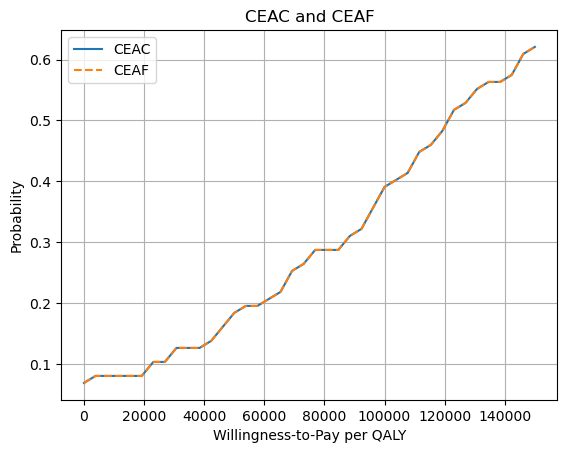

In [85]:
def run_archived_fragment_72(*, prob, wtp):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    import numpy as np  # Import numpy for this operation

    # %% [markdown]
    ## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

    print("\n--- Running Module 15: CEAF ---")
    # Reuse 'prob' (CEAC probabilities) from Module 8
    prob_host = prob.get()  # Get the CuPy array to host memory (NumPy array)
    ceaf = np.maximum.accumulate(prob_host)  # Use numpy for the accumulate operation

    plt.figure()
    plt.plot(wtp.get(), prob.get(), label="CEAC")
    plt.plot(
        wtp.get(), ceaf, label="CEAF", linestyle="--"
    )  # ceaf is already a NumPy array
    plt.title("CEAC and CEAF")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("Probability")
    plt.legend()
    plt.grid(True)
    plt.show()
    return locals()

# %% [markdown]
## 16. Input Parameter Summary

print("\n--- Running Module 16: Saving Input Parameter Summary ---")
params_summary = {
    "DISCOUNT": DISCOUNT,
    "default_yield": defaul_yield,
    "U_DIAG": U_DIAG,
    "U_CARER": U_CARER,
    "RESPITE": RESPITE,
    "MOBILITY": MOBILITY,
    "FERT_AGE_SPEC": json.dumps(
        {f"{k[0]}_{k[1][0]}_{k[1][1]}": v for k, v in FERT_AGE_SPEC.items()}
    ),
    "MORB_PROB": json.dumps(MORB_PROB),
    "AGE_DIST": json.dumps(AGE_DIST.get().tolist()),
}

param_df = cudf.DataFrame(
    {
        "parameter": list(params_summary.keys()),
        "value": [str(v) for v in params_summary.values()],
    }
)

param_df.to_csv("input_summary.csv", index=False)
print("Input parameters saved to input_summary.csv")

# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
# Published point estimates for comparison
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}

pub_rows = []
for scen, vals in published.items():
    pub_rows.append(
        {
            "scenario": scen,
            "dCost_pub": vals["dCost"],
            "dQALY_pub": vals["dQALY"],
            "ICER_pub": vals["ICER"],
        }
    )
pub_df = cudf.DataFrame(pub_rows)

# Merge with your deterministic simulation output (det_df from Module 6)
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)

print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_pandas().to_string())  # Use pandas for cleaner console printing
df_cmp.to_csv("publication_comparison.csv", index=False)
print("Saved comparison to publication_comparison.csv")

# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
# Published point estimates for comparison
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}

pub_rows = []
for scen, vals in published.items():
    pub_rows.append(
        {
            "scenario": scen,
            "dCost_pub": vals["dCost"],
            "dQALY_pub": vals["dQALY"],
            "ICER_pub": vals["ICER"],
        }
    )
pub_df = cudf.DataFrame(pub_rows)

# Merge with your deterministic simulation output (det_df from Module 6)
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)

print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_pandas().to_string())  # Use pandas for cleaner console printing
df_cmp.to_csv("publication_comparison.csv", index=False)
print("Saved comparison to publication_comparison.csv")